# Análise de Vendas — E-commerce

Análise de desempenho comercial de um e-commerce de artigos esportivos a partir da exportação de pedidos da plataforma VTEX.

> **Os dados são fictícios.** Foram gerados pelo script `gerar_dados_ficticios.py`, que reproduz a estrutura e os problemas de qualidade de uma base real (pedidos divididos em pacotes, status e UFs digitados de formas diferentes, colunas vazias).

**Indicadores:** faturamento, ticket médio, produtos mais vendidos, evolução diária, distribuição por estado e taxa de cancelamento.

**Ferramentas:** Python, pandas, matplotlib.

## Configuração

In [1]:
import os

import matplotlib.dates as mdates
import matplotlib.pyplot as plt
import pandas as pd

CAMINHO_EXCEL = "vendas_ficticias.xlsx"
CAMINHO_PARQUET = "vendas_ficticias.parquet"

AZUL = "#2a78d6"
CINZA_TEXTO = "#52514e"
CINZA_GRADE = "#e1e0d9"
CINZA_CLARO = "#c3c2b7"


def formatar_reais(valor):
    return f"R$ {valor:,.2f}".replace(",", "X").replace(".", ",").replace("X", ".")


def formatar_numero(valor):
    return f"{valor:,.0f}".replace(",", ".")


def estilo(ax, titulo, eixo_x="", eixo_y=""):
    ax.set_title(titulo, loc="left", fontsize=14)
    ax.set_xlabel(eixo_x, color=CINZA_TEXTO)
    ax.set_ylabel(eixo_y, color=CINZA_TEXTO)
    ax.spines[["top", "right", "left"]].set_visible(False)
    ax.spines["bottom"].set_color(CINZA_CLARO)
    ax.set_axisbelow(True)
    ax.tick_params(colors=CINZA_TEXTO, length=0)

## 1. Carga dos dados

A leitura de Excel é lenta em bases grandes. A base é convertida uma vez para Parquet, e o Excel só é relido quando for mais recente que o Parquet.

In [2]:
if os.path.exists(CAMINHO_PARQUET) and os.path.getmtime(CAMINHO_PARQUET) > os.path.getmtime(CAMINHO_EXCEL):
    print("Base em cache atualizada.")
else:
    print("Excel novo ou alterado. Reprocessando a base...")
    bruto = pd.read_excel(CAMINHO_EXCEL, sheet_name="BD", engine="calamine")
    colunas_texto = bruto.select_dtypes(include=["object", "str"]).columns
    bruto[colunas_texto] = bruto[colunas_texto].astype("str")
    bruto.to_parquet(CAMINHO_PARQUET)
    del bruto

df = pd.read_parquet(CAMINHO_PARQUET)
print(f"Base carregada: {formatar_numero(len(df))} linhas × {df.shape[1]} colunas")

Base em cache atualizada.
Base carregada: 69.676 linhas × 22 colunas


## 2. Tratamento dos dados

| Problema encontrado | Tratamento |
|---|---|
| Colunas sem nenhum valor preenchido | removidas |
| Nomes de colunas em inglês e com espaços | renomeadas para português |
| Mesmo status escrito de formas diferentes (`Pagamento Aprovado` / `Pagamento aprovado`) | padronizados |
| Variações de cancelamento (`Cancelar`, `Cancelamento Solicitado`, ...) | agrupadas em `Cancelado` |
| UF digitada de várias formas (`sp`, `SP `, `São Paulo`, `bahia`...) | padronizada na sigla |
| Nome do produto inclui o tamanho (`- M`, `- 39/40`) | criada a coluna `modelo`, sem o tamanho |

**Estrutura da base (regras de negócio):**
- Cada linha é um **item**. Um **pacote** (`25005000001-01`) agrupa itens, e um **pedido** (`25005000001`) pode ser dividido em vários pacotes, enviados por lojas diferentes.
- O valor total (`valor_pacote`) é **por pacote** e se repete em cada item. Somar a coluna diretamente inflaria o faturamento. Os valores são somados uma vez por pacote, e os pedidos são contados de forma distinta.

In [3]:
colunas_vazias = df.columns[df.isna().all()]
df = df.drop(columns=colunas_vazias)

df = df.rename(columns={
    "Order": "pacote",
    "Creation D": "data_pedido",
    "Status": "status",
    "UF": "uf",
    "Região": "regiao",
    "SKU Name": "produto",
    "Peças": "quantidade",
    "SKU Selling Price": "preco_unitario",
    "SKU Total Price": "preco_total",
    "Total Value": "valor_pacote",
    "Seller Name": "loja",
    "Cancellation Reason": "motivo_cancelamento",
    "Canal": "canal",
})

ajustes_status = {
    "Cancelar": "Cancelado",
    "Cancelamento solicitado": "Cancelado",
    "Aguardando para alterar seller": "Cancelado",
    "Admin / orders.order-status.": "Cancelado",
    "Pronto para manuseio": "Pronto para o manuseio",
}
df["status"] = df["status"].str.capitalize().replace(ajustes_status)

nomes_estados = {
    "SÃO PAULO": "SP",
    "MINAS GERAIS": "MG",
    "RIO DE JANEIRO": "RJ",
    "BAHIA": "BA",
    "PARÁ": "PA",
    "PÉ": "PE",
}
df["uf"] = df["uf"].str.strip().str.upper().replace(nomes_estados)

df["pedido"] = df["pacote"].str.split("-").str[0]
df["modelo"] = df["produto"].str.rsplit(" - ", n=1).str[0]

print(f"Colunas vazias removidas: {list(colunas_vazias)}")

Colunas vazias removidas: ['GiftRegistry ID', 'List Id', 'Taxes']


**Verificações de qualidade** — se algum item aparecer com ❌, a base trouxe um valor novo que precisa ser incluído no tratamento acima.

In [4]:
STATUS_VALIDOS = {
    "Faturado", "Pagamento aprovado", "Preparando entrega", "Pagamento pendente",
    "Verificando fatura", "Verificando nota fiscal", "Pronto para o manuseio",
    "Aguardando decisão do seller", "Aguardando troca do seller", "Cancelado",
}
UFS_VALIDAS = {
    "AC", "AL", "AM", "AP", "BA", "CE", "DF", "ES", "GO", "MA", "MG", "MS", "MT", "PA",
    "PB", "PE", "PI", "PR", "RJ", "RN", "RO", "RR", "RS", "SC", "SE", "SP", "TO",
}

verificacoes = {
    "Todos os status reconhecidos": set(df["status"].unique()) <= STATUS_VALIDOS,
    "Todas as UFs reconhecidas": set(df["uf"].unique()) <= UFS_VALIDAS,
    "Valor do pacote igual em todos os itens do pacote": (df.groupby("pacote")["valor_pacote"].nunique() == 1).all(),
    "Sem pedidos sem data": df["data_pedido"].notna().all(),
}

for descricao, ok in verificacoes.items():
    print("✅" if ok else "❌", descricao)

desconhecidos = (set(df["status"].unique()) - STATUS_VALIDOS) | (set(df["uf"].unique()) - UFS_VALIDAS)
if desconhecidos:
    print("Valores não reconhecidos:", sorted(desconhecidos))

✅ Todos os status reconhecidos
✅ Todas as UFs reconhecidas
✅ Valor do pacote igual em todos os itens do pacote
✅ Sem pedidos sem data


In [5]:
pacotes = df.drop_duplicates(subset="pacote").copy()
pacotes["cancelado"] = pacotes["status"] == "Cancelado"
pacotes_validos = pacotes[~pacotes["cancelado"]]

itens_validos = df[df["status"] != "Cancelado"]

pedidos = pacotes.groupby("pedido").agg(
    data_pedido=("data_pedido", "min"),
    cancelado=("cancelado", "min"),
)

soma_errada = df["valor_pacote"].sum()
soma_correta = pacotes["valor_pacote"].sum()

print(f"Itens:   {formatar_numero(len(df))}")
print(f"Pacotes: {formatar_numero(len(pacotes))}")
print(f"Pedidos: {formatar_numero(len(pedidos))}")
print()
print(f"Somar valor_pacote em todas as linhas daria {formatar_reais(soma_errada)}, "
      f"{soma_errada / soma_correta:.1f}× o valor correto ({formatar_reais(soma_correta)}).")

Itens:   69.676
Pacotes: 44.882
Pedidos: 38.429

Somar valor_pacote em todas as linhas daria R$ 36.028.308,14, 2.0× o valor correto (R$ 18.222.465,49).


## 3. Indicadores

### 3.1 Visão geral

- **Faturamento líquido** e **ticket médio** desconsideram pacotes cancelados.
- Um pedido é considerado **cancelado** quando todos os seus pacotes foram cancelados.

In [6]:
faturamento_bruto = pacotes["valor_pacote"].sum()
faturamento_liquido = pacotes_validos["valor_pacote"].sum()
qtd_pedidos_validos = pacotes_validos["pedido"].nunique()
ticket_medio = faturamento_liquido / qtd_pedidos_validos
taxa_cancelamento = pedidos["cancelado"].mean() * 100

primeiro_dia = df["data_pedido"].min().strftime("%d/%m/%Y")
ultimo_dia = df["data_pedido"].max().strftime("%d/%m/%Y")

indicadores = pd.DataFrame({
    "Indicador": [
        "Período",
        "Faturamento bruto",
        "Faturamento líquido (sem cancelados)",
        "Pedidos válidos",
        "Ticket médio por pedido",
        "Taxa de cancelamento (pedidos)",
    ],
    "Valor": [
        f"{primeiro_dia} a {ultimo_dia}",
        formatar_reais(faturamento_bruto),
        formatar_reais(faturamento_liquido),
        formatar_numero(qtd_pedidos_validos),
        formatar_reais(ticket_medio),
        f"{taxa_cancelamento:.1f}%".replace(".", ","),
    ],
})

indicadores.set_index("Indicador")

,Valor
Indicador,
Período,01/01/2025 a 31/12/2025
Faturamento bruto,"R$ 18.222.465,49"
Faturamento líquido (sem cancelados),"R$ 16.996.860,84"
Pedidos válidos,36.189
Ticket médio por pedido,"R$ 469,67"
Taxa de cancelamento (pedidos),"5,8%"


### 3.2 Produtos mais vendidos

Ranking por modelo (todos os tamanhos somados), sem pacotes cancelados.

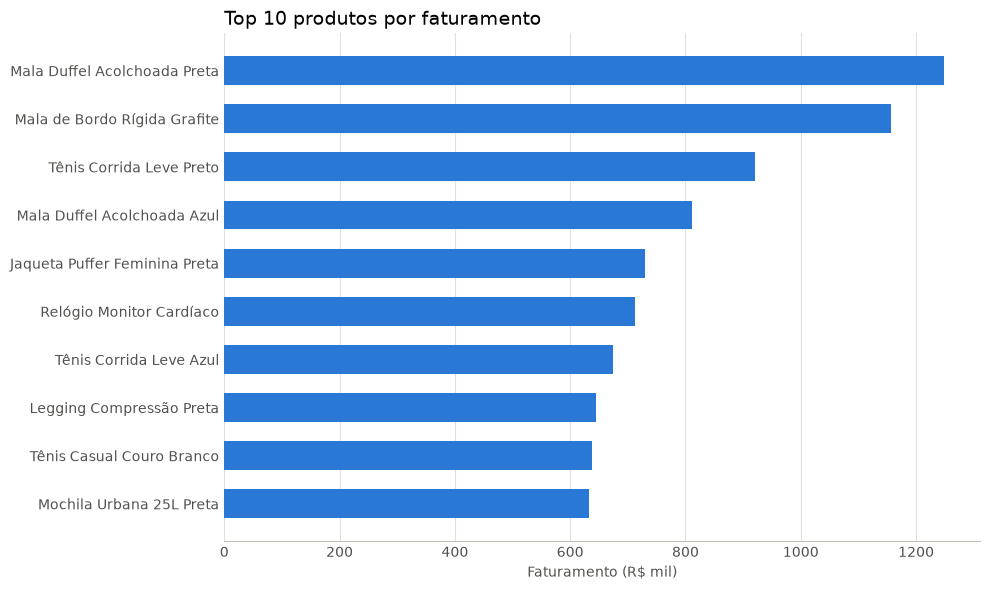

In [7]:
top_produtos = itens_validos.groupby("modelo")["preco_total"].sum().sort_values(ascending=False).head(10)

dados = top_produtos.sort_values() / 1000

fig, ax = plt.subplots(figsize=(10, 6))
ax.barh(dados.index, dados.values, color=AZUL, height=0.6)
ax.grid(axis="x", color=CINZA_GRADE)
estilo(ax, "Top 10 produtos por faturamento", eixo_x="Faturamento (R$ mil)")

plt.tight_layout()
plt.show()

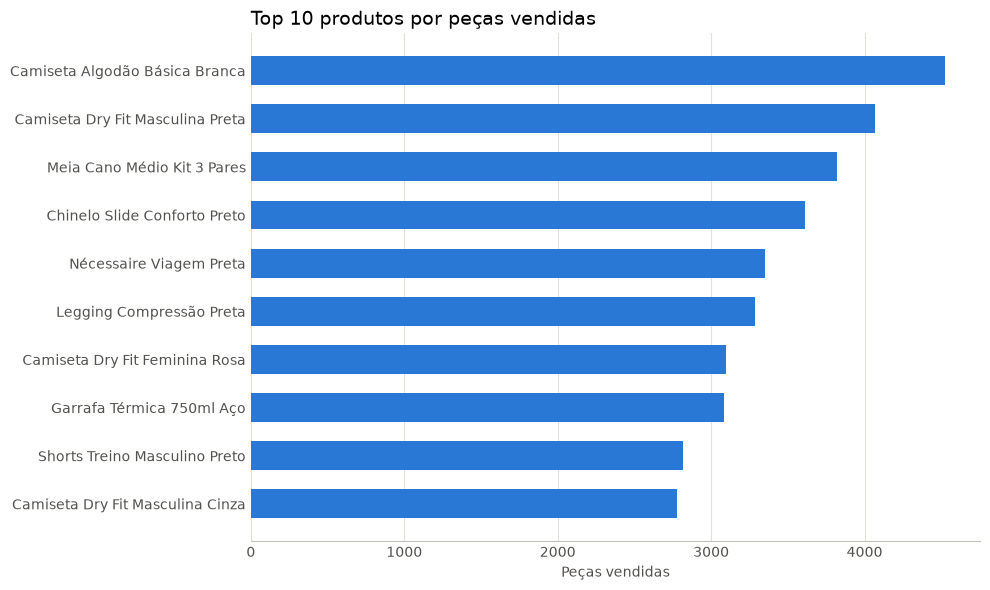

Produtos presentes nos dois rankings: 1 de 10


In [8]:
top_quantidade = itens_validos.groupby("modelo")["quantidade"].sum().sort_values(ascending=False).head(10)

dados = top_quantidade.sort_values()

fig, ax = plt.subplots(figsize=(10, 6))
ax.barh(dados.index, dados.values, color=AZUL, height=0.6)
ax.grid(axis="x", color=CINZA_GRADE)
estilo(ax, "Top 10 produtos por peças vendidas", eixo_x="Peças vendidas")

plt.tight_layout()
plt.show()

em_comum = top_quantidade.index.isin(top_produtos.index).sum()
print(f"Produtos presentes nos dois rankings: {em_comum} de 10")

### 3.3 Evolução diária

Faturamento líquido por dia (cinza) e média móvel de 7 dias (azul).

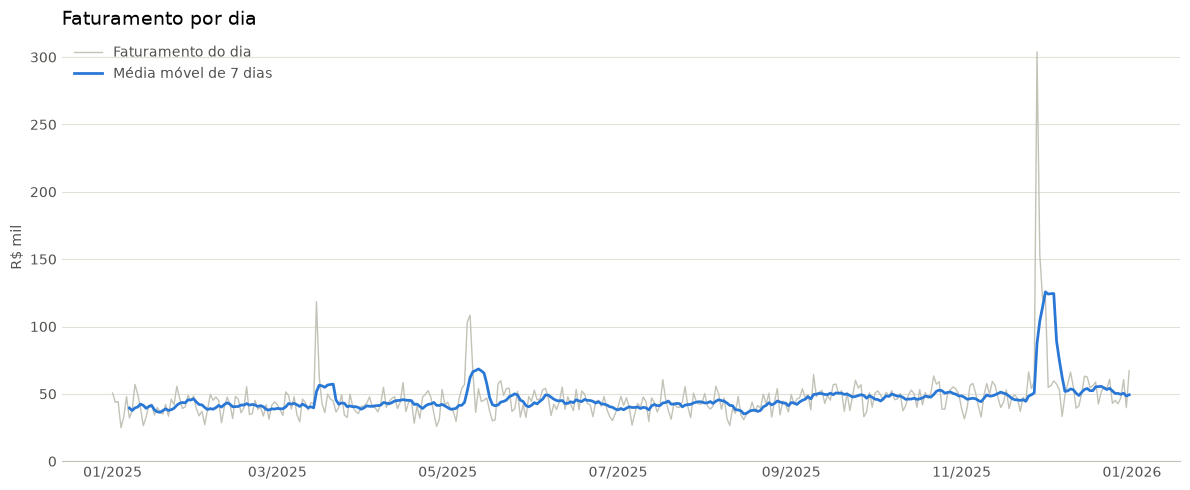

Dia típico (mediana): R$ 44.379,35
Dias de maior faturamento:
  28/11/2025: R$ 303.829,91
  29/11/2025: R$ 153.286,94
  01/12/2025: R$ 123.127,89
  30/11/2025: R$ 120.415,72
  15/03/2025: R$ 118.430,76


In [9]:
vendas_dia = pacotes_validos.groupby("data_pedido")["valor_pacote"].sum() / 1000
media_7_dias = vendas_dia.rolling(7).mean()

fig, ax = plt.subplots(figsize=(12, 5))
ax.plot(vendas_dia.index, vendas_dia.values, color=CINZA_CLARO, linewidth=1, label="Faturamento do dia")
ax.plot(media_7_dias.index, media_7_dias.values, color=AZUL, linewidth=2, label="Média móvel de 7 dias")
ax.set_ylim(bottom=0)
ax.xaxis.set_major_formatter(mdates.DateFormatter("%m/%Y"))
ax.grid(axis="y", color=CINZA_GRADE)
ax.legend(frameon=False, loc="upper left", labelcolor=CINZA_TEXTO)
estilo(ax, "Faturamento por dia", eixo_y="R$ mil")

plt.tight_layout()
plt.show()

print(f"Dia típico (mediana): {formatar_reais(vendas_dia.median() * 1000)}")
print("Dias de maior faturamento:")
for dia, valor in vendas_dia.sort_values(ascending=False).head(5).items():
    print(f"  {dia.strftime('%d/%m/%Y')}: {formatar_reais(valor * 1000)}")

### 3.4 Distribuição por estado

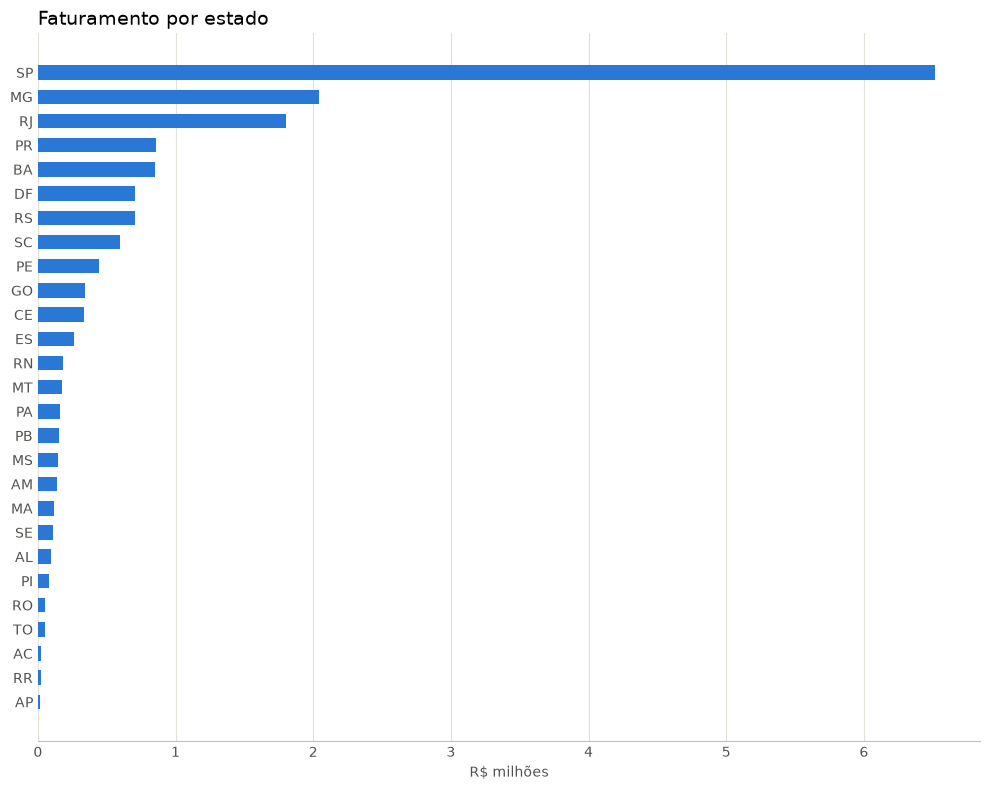

Participação no faturamento:
  SP: 38,3%
  MG: 12,0%
  RJ: 10,6%
  PR: 5,0%
  BA: 5,0%
  Top 3 somados: 61,0%


In [10]:
vendas_uf = pacotes_validos.groupby("uf")["valor_pacote"].sum().sort_values(ascending=False)
participacao_uf = vendas_uf / vendas_uf.sum() * 100

dados = vendas_uf.sort_values() / 1_000_000

fig, ax = plt.subplots(figsize=(10, 8))
ax.barh(dados.index, dados.values, color=AZUL, height=0.6)
ax.grid(axis="x", color=CINZA_GRADE)
estilo(ax, "Faturamento por estado", eixo_x="R$ milhões")

plt.tight_layout()
plt.show()

print("Participação no faturamento:")
for uf, pct in participacao_uf.head(5).items():
    print(f"  {uf}: {pct:.1f}%".replace(".", ","))
print(f"  Top 3 somados: {participacao_uf.head(3).sum():.1f}%".replace(".", ","))

### 3.5 Cancelamentos

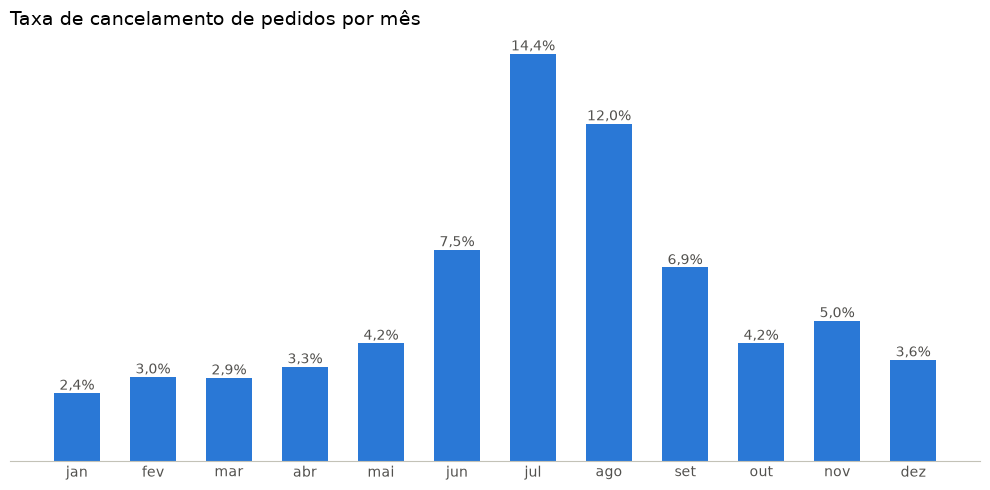

In [11]:
pedidos["mes"] = pedidos["data_pedido"].dt.month
taxa_mes = pedidos.groupby("mes")["cancelado"].mean() * 100

nomes_meses = ["jan", "fev", "mar", "abr", "mai", "jun", "jul", "ago", "set", "out", "nov", "dez"]
rotulos = [nomes_meses[mes - 1] for mes in taxa_mes.index]

fig, ax = plt.subplots(figsize=(10, 5))
ax.bar(rotulos, taxa_mes.values, color=AZUL, width=0.6)

for posicao, valor in enumerate(taxa_mes.values):
    ax.text(posicao, valor, f"{valor:.1f}%".replace(".", ","), ha="center", va="bottom", color=CINZA_TEXTO)

ax.set_yticks([])
estilo(ax, "Taxa de cancelamento de pedidos por mês")

plt.tight_layout()
plt.show()

**Motivos de cancelamento:** distribuição dos motivos nos meses de pico (jun–ago) comparada ao restante do ano.

In [12]:
cancelados = pacotes[pacotes["cancelado"]].copy()
cancelados["periodo"] = cancelados["data_pedido"].dt.month.isin([6, 7, 8]).map({True: "Jun–Ago", False: "Demais meses"})

motivos = pd.crosstab(cancelados["motivo_cancelamento"], cancelados["periodo"], normalize="columns") * 100
motivos = motivos[["Demais meses", "Jun–Ago"]].sort_values("Jun–Ago", ascending=False)

motivos.round(1).astype(str) + "%"

periodo,Demais meses,Jun–Ago
motivo_cancelamento,,
Atraso na entrega,20.9%,60.0%
Desistência do cliente,39.4%,19.2%
Pagamento não aprovado,20.9%,11.4%
Falta de estoque,18.8%,9.4%


## 4. Principais conclusões

1. **Cancelamentos com causa identificável:** a taxa de cancelamento de pedidos saiu de **2,4% em janeiro** para **14,4% em julho** e voltou a ~4% no fim do ano. Nos meses de pico (jun–ago), **60% dos cancelamentos foram por atraso na entrega**, contra 21% no restante do ano. Isso aponta para um problema logístico no período, não para uma mudança no comportamento do cliente.
2. **Black Friday concentra o ano:** 28/11 faturou **R$ 303,8 mil**, cerca de **7×** um dia típico (R$ 44,4 mil). Dia do Consumidor (15/03) e Dia das Mães (maio) também geram picos claros. A operação e o estoque precisam ser dimensionados para essas datas.
3. **Crescimento ao longo do ano:** a média móvel de faturamento diário sobe de ~R$ 40 mil em janeiro para ~R$ 50 mil em dezembro.
4. **Concentração geográfica:** **SP** responde por **38%** do faturamento; SP, MG e RJ somam **61%**.
5. **Faturamento ≠ volume:** só 1 produto aparece nos dois rankings. Malas e tênis lideram em faturamento (ticket alto), enquanto camisetas, meias e chinelos lideram em peças vendidas. São produtos que atraem o cliente e podem ser usados em combos com os itens de maior valor.
6. **Ticket médio de R$ 469,67** por pedido, com 36,2 mil pedidos válidos e R$ 17,0 milhões de faturamento líquido.
